In [1]:
# Comprobar las tablas de la capa Gold
tablas = ["fact_aire", "dim_contaminante", "dim_estacion", "dim_tiempo"]

for tabla in tablas:
    df = spark.table(tabla)

    print(f"\nTabla: {tabla}")
    print(f"Registros: {df.count()}")
    df.printSchema()
    display(df.limit(5))

StatementMeta(, 7bb5f8e4-90dd-46b0-af56-ce1e9f3a217a, 3, Finished, Available, Finished, False)


Tabla: fact_aire
Registros: 2215570
root
 |-- id_tiempo: integer (nullable = false)
 |-- id_estacion: string (nullable = false)
 |-- id_contaminante: integer (nullable = false)
 |-- id_distrito: integer (nullable = true)
 |-- concentracion: double (nullable = true)



SynapseWidget(Synapse.DataFrame, f71f283b-f6e6-4eb6-9fd2-fb375f75d599)


Tabla: dim_contaminante
Registros: 4
root
 |-- id_contaminante: integer (nullable = false)
 |-- nombre: string (nullable = true)
 |-- unidad: string (nullable = true)
 |-- indicador: string (nullable = true)
 |-- limite_ue_actual: double (nullable = true)
 |-- objetivo_ue_2030: double (nullable = true)
 |-- guia_oms_2021: double (nullable = true)



SynapseWidget(Synapse.DataFrame, 9b728c5d-bd5d-4f4d-858c-5ebd6c03b771)


Tabla: dim_estacion
Registros: 11
root
 |-- id_estacion: string (nullable = false)
 |-- codigo_eea: string (nullable = true)
 |-- nombre_estacion: string (nullable = true)
 |-- tipo_estacion: string (nullable = true)
 |-- zona: string (nullable = true)
 |-- latitud: double (nullable = true)
 |-- longitud: double (nullable = true)
 |-- altitud: double (nullable = true)
 |-- fecha_alta: date (nullable = true)
 |-- fecha_baja: date (nullable = true)
 |-- activa: boolean (nullable = true)
 |-- id_distrito: integer (nullable = true)



SynapseWidget(Synapse.DataFrame, 861e78ea-ee66-471f-8a6e-eb059f4897dd)


Tabla: dim_tiempo
Registros: 131472
root
 |-- id_tiempo: integer (nullable = false)
 |-- fecha_hora: timestamp (nullable = false)
 |-- fecha: date (nullable = false)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)
 |-- dia: integer (nullable = true)
 |-- hora: integer (nullable = true)
 |-- es_fin_de_semana: boolean (nullable = true)
 |-- es_festivo: boolean (nullable = true)
 |-- nombre_festivo: string (nullable = true)
 |-- es_evento: boolean (nullable = true)
 |-- nombre_evento: string (nullable = true)
 |-- es_confinamiento: boolean (nullable = true)
 |-- dia_semana: integer (nullable = true)
 |-- nombre_dia: string (nullable = true)
 |-- nombre_mes: string (nullable = true)
 |-- trimestre: integer (nullable = true)



SynapseWidget(Synapse.DataFrame, ded7e7e8-3883-4d6c-9db0-9c75e4cc5ffd)

In [4]:
from pyspark.sql import functions as F

# Cargar las tablas
aire = spark.table("fact_aire")
tiempo = spark.table("dim_tiempo")
contaminantes = spark.table("dim_contaminante")

# Relacionar las tablas
df_analisis = (aire
    .join(tiempo.select("id_tiempo", "anio"), "id_tiempo", "left")
    .join(contaminantes.select("id_contaminante", "nombre"), "id_contaminante", "left")
)

# Resumen de disponibilidad de datos
resumen = (df_analisis.groupBy("anio", "nombre")
    .agg(
        F.count("*").alias("total_registros"),
        F.count("concentracion").alias("registros_validos"),
        F.sum(F.col("concentracion").isNull().cast("int")).alias("registros_nulos"),
        F.countDistinct("id_estacion").alias("num_estaciones")
    )
    .orderBy("anio", "nombre")
)

display(resumen)

StatementMeta(, 7bb5f8e4-90dd-46b0-af56-ce1e9f3a217a, 6, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, ad1d60ae-6182-4d73-90fd-b745a0f820e0)

In [5]:
# Comprobar la cobertura temporal por estación
df_cobertura = (df_analisis
    .filter(F.col("anio").between(2013, 2025) & F.col("nombre").isin("NO2", "PM10", "PM2.5"))
    .join(spark.table("dim_estacion").select("id_estacion", "nombre_estacion"), "id_estacion", "left")
    .groupBy("anio", "nombre", "id_estacion", "nombre_estacion")
    .agg(
        F.countDistinct("id_tiempo").alias("horas_con_datos"),
        F.count("*").alias("registros")
    )
    .withColumn("horas_esperadas", F.when(F.col("anio") % 4 == 0, 8784).otherwise(8760))
    .withColumn("cobertura_pct", F.round(F.col("horas_con_datos") / F.col("horas_esperadas") * 100, 2))
    .orderBy("anio", "nombre", "nombre_estacion")
)

display(df_cobertura)

StatementMeta(, 7bb5f8e4-90dd-46b0-af56-ce1e9f3a217a, 7, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, b69d0d05-b19d-4cfa-a685-9c017b7e4845)

In [6]:
# Calcular las medias anuales
medias = (df_analisis
    .filter(F.col("anio").between(2013, 2025) & F.col("nombre").isin("NO2", "PM10", "PM2.5"))
    .groupBy("anio", "nombre", "id_estacion")
    .agg(F.round(F.avg("concentracion"), 2).alias("media_anual"))
)

# Incorporar la cobertura y el nombre de la estación
medias = medias.join(
    df_cobertura.select("anio", "nombre", "id_estacion", "nombre_estacion", "cobertura_pct"),
    ["anio", "nombre", "id_estacion"], "inner"
)

# Seleccionar las series con cobertura mínima del 75 %
medias_validas = medias.filter(F.col("cobertura_pct") >= 75)

# Añadir los valores de referencia
referencias = spark.table("dim_contaminante").select(
    "nombre", "limite_ue_actual", "objetivo_ue_2030", "guia_oms_2021"
)

# Calcular la distancia respecto al objetivo europeo de 2030
resultado = (
    medias_validas.join(referencias, "nombre", "left")
    .withColumn("distancia_2030", F.round(F.col("media_anual") - F.col("objetivo_ue_2030"), 2))
    .withColumn("distancia_pct_2030", F.round(
        (F.col("media_anual") / F.col("objetivo_ue_2030") - 1) * 100, 2
    ))
    .orderBy("anio", "nombre", "nombre_estacion")
)

display(resultado)

StatementMeta(, 7bb5f8e4-90dd-46b0-af56-ce1e9f3a217a, 8, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 23e8a956-b04d-4882-b958-9bab6c86e761)

StatementMeta(, 7bb5f8e4-90dd-46b0-af56-ce1e9f3a217a, 12, Finished, Available, Finished, False)

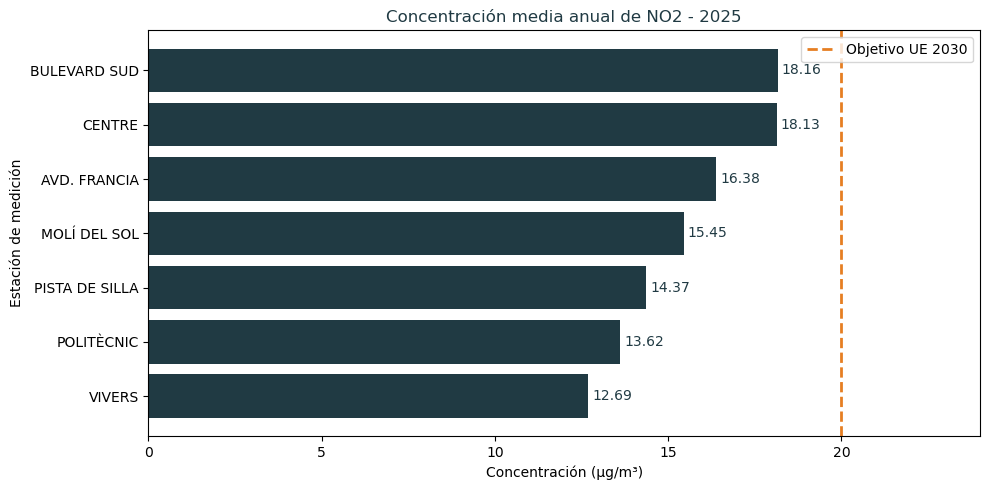

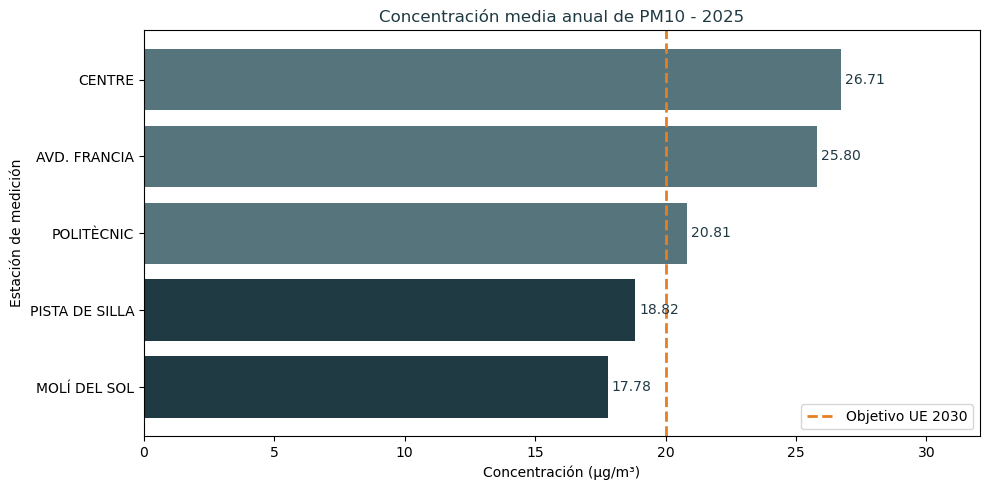

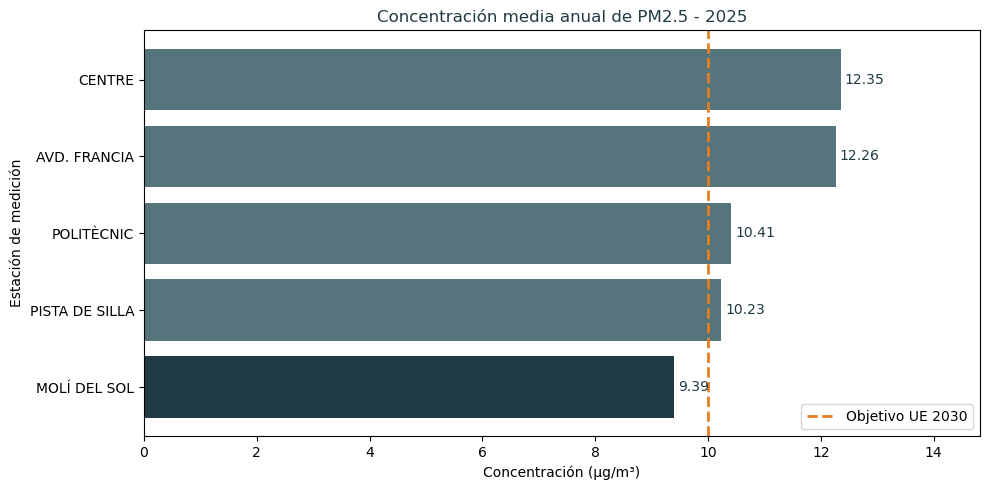

In [7]:
import matplotlib.pyplot as plt
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores
azul = "#203A43"
azul_gris = "#56747B"
naranja = "#E67E22"

# Seleccionar los datos de 2025
pdf = resultado.toPandas()
datos_2025 = pdf[pdf["anio"] == 2025]

for cont in ["NO2", "PM10", "PM2.5"]:
    d = datos_2025[datos_2025["nombre"] == cont].sort_values("media_anual")
    objetivo = d["objetivo_ue_2030"].iloc[0]

    # Diferenciar las estaciones que superan el objetivo
    colores = [azul_gris if valor > objetivo else azul for valor in d["media_anual"]]

    fig, ax = plt.subplots(figsize=(10, 5))
    barras = ax.barh(d["nombre_estacion"], d["media_anual"], color=colores)

    ax.axvline(objetivo, color=naranja, linestyle="--", linewidth=2, label="Objetivo UE 2030")
    ax.bar_label(barras, fmt="%.2f", padding=3, color=azul)

    ax.set_title(f"Concentración media anual de {cont} - 2025", color=azul)
    ax.set_xlabel("Concentración (µg/m³)")
    ax.set_ylabel("Estación de medición")
    ax.set_xlim(0, max(d["media_anual"].max(), objetivo) * 1.2)
    ax.legend()

    plt.tight_layout()
    plt.savefig(f"{ruta}/media_anual_{cont}_2025.png", dpi=300, bbox_inches="tight")
    plt.show()

StatementMeta(, 7bb5f8e4-90dd-46b0-af56-ce1e9f3a217a, 21, Finished, Available, Finished, False)

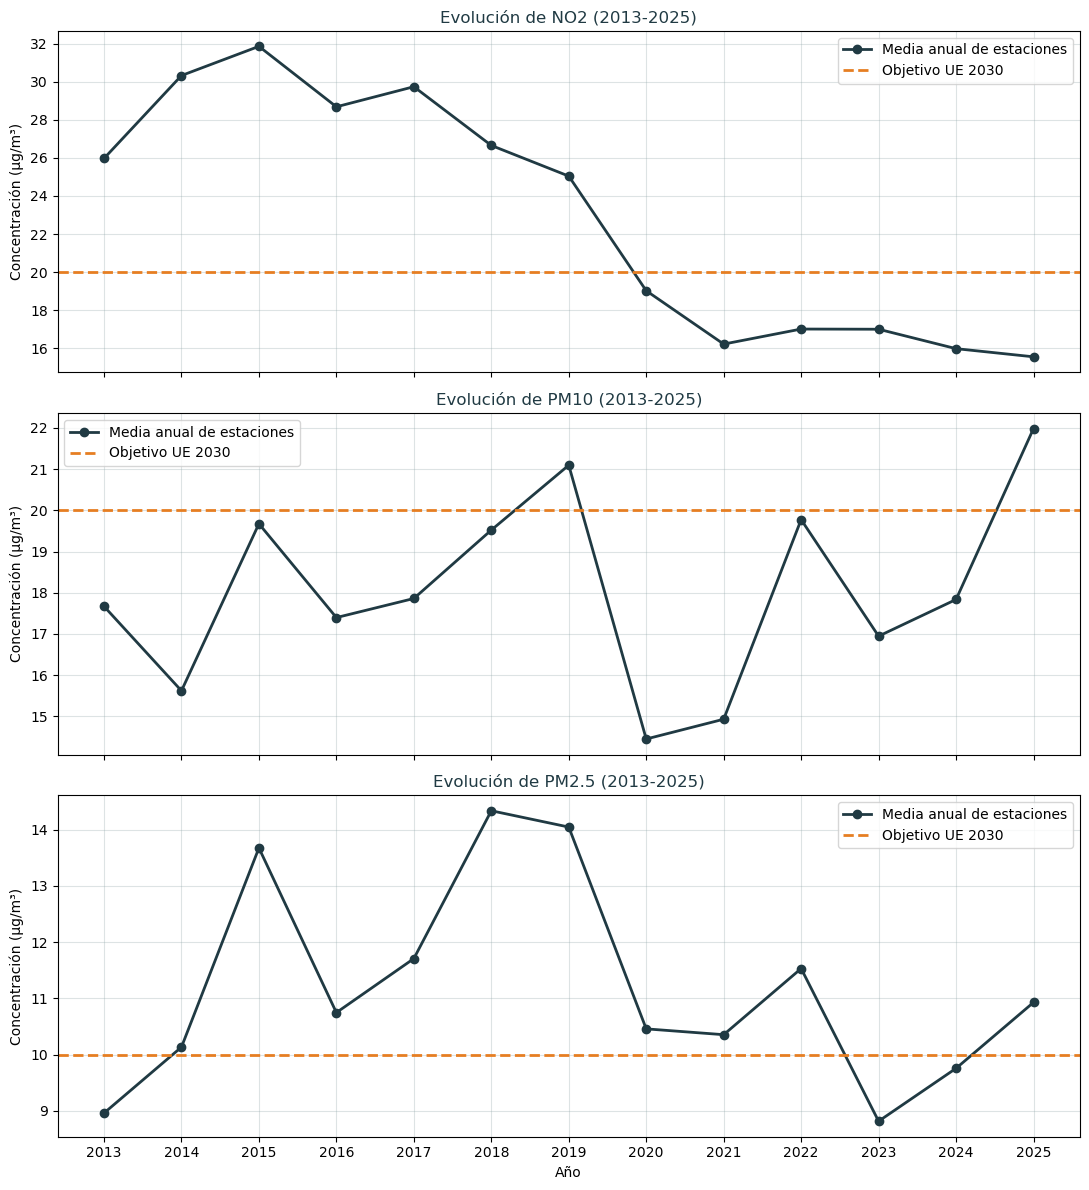

In [8]:
import matplotlib.pyplot as plt
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores
azul = "#203A43"
gris = "#8FA5A8"
naranja = "#E67E22"

# Calcular la media anual de las estaciones
pdf = resultado.toPandas()

evolucion = (pdf.groupby(["anio", "nombre"])
    .agg(
        media=("media_anual", "mean"),
        objetivo=("objetivo_ue_2030", "first"),
        estaciones=("id_estacion", "nunique")
    )
    .reset_index()
)

# Crear tres gráficos verticales
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for ax, cont in zip(axes, ["NO2", "PM10", "PM2.5"]):
    d = evolucion[evolucion["nombre"] == cont].sort_values("anio")

    ax.plot(d["anio"], d["media"], color=azul, marker="o",
            linewidth=2, label="Media anual de estaciones")

    ax.axhline(d["objetivo"].iloc[0], color=naranja, linestyle="--",
               linewidth=2, label="Objetivo UE 2030")

    ax.set_title(f"Evolución de {cont} (2013-2025)", color=azul)
    ax.set_ylabel("Concentración (µg/m³)")
    ax.grid(color=gris, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Año")
axes[-1].set_xticks(range(2013, 2026))

plt.tight_layout()

# Guardar PNG
plt.savefig(f"{ruta}/04_evolucion_anual_contaminantes_2013_2025.png",
            dpi=300, bbox_inches="tight")
plt.show()